# Super-Resolution Interpolation Comparison (x3)

This notebook takes an image dataset, downscales the **Y (luma)** channel of every image by a factor of 3 using **bicubic** interpolation, and then upscales it back by 3 using six different interpolation methods. The **Cb** and **Cr** chroma channels are only used for display (bicubic).

The metrics follow **exactly the same protocol as the SRCNN notebook**, so the numbers can be compared directly:
- PSNR / SSIM are computed on the **Y channel only**
- a border of `SCALE` pixels is **shaved** before computing the metrics
- SSIM uses an 11x11 Gaussian window (sigma = 1.5)

Sanity check: the **Bicubic** row here must equal the **Bicubic** row of the SRCNN notebook (Set14, x3: PSNR 26.306, SSIM 0.7561).

## 1. Imports

Import the libraries used for file handling, image processing, metric computation, and plotting.

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import scipy.ndimage as ndimage
import matplotlib.patches as patches
from matplotlib.gridspec import GridSpec

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("jesucristo/super-resolution-benchmarks")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/jesucristo/super-resolution-benchmarks


## 2. Configuration

- `DATASET_DIR`: path to the dataset folder (on Kaggle it is usually `/kaggle/input/<dataset-name>`). Sub-folders are searched recursively.
- `SCALE`: the downscale / upscale factor.
- `MAX_IMAGES`: maximum number of images to process (set to `None` to use the whole dataset).
- `SHOW_INDEX`: index of the image that will be visualized in the 2x3 subplot.

In [3]:
DATASET_DIR = '/kaggle/input/datasets/jesucristo/super-resolution-benchmarks/Set14/Set14/original'
SCALE = 3
MAX_IMAGES = 50
SHOW_INDEX = 0
EXTENSIONS = ("png", "jpg", "jpeg")

## 3. Interpolation Methods

Define the six interpolation methods used to upscale the Y channel. Each name is mapped to the corresponding Pillow resampling filter. Bicubic is also defined separately for downscaling and for the Cb/Cr channels.

In [4]:
def mitchell_netravali_kernel(x, B=1/3, C=1/3):
    x = np.abs(x)
    if x < 1:
        return ((12 - 9*B - 6*C) * x**3 + (-18 + 12*B + 6*C) * x**2 + (6 - 2*B)) / 6
    elif 1 <= x < 2:
        return ((-B - 6*C) * x**3 + (6*B + 30*C) * x**2 + (-12*B - 48*C) * x + (8*B + 24*C)) / 6
    else:
        return 0.0

def upscale_mitchell(y_channel, scale):
    y_np = np.asarray(y_channel, dtype=np.float32)
    y_up_np = ndimage.zoom(y_np, scale, order=3)
    y_up_np = np.clip(y_up_np, 0, 255).astype(np.uint8)
    return Image.fromarray(y_up_np)

In [5]:
def upscale_y(y_lr, scale, y_method):
    """Upscale a low-resolution Y channel (PIL 'L' image) with the chosen method."""
    w, h = y_lr.size
    if y_method == "Mitchell-Netravali":
        return upscale_mitchell(y_lr, scale)
    return y_lr.resize((w * scale, h * scale), y_method)

In [6]:
R = Image.Resampling

METHODS = {
    "Nearest Neighbor": R.NEAREST,
    "Mitchell-Netravali": "Mitchell-Netravali",
    "Hamming": R.HAMMING,
    "Bicubic": R.BICUBIC,
    "Bilinear": R.BILINEAR,
    "Lanczos": R.LANCZOS,
}

CHROMA_METHOD = R.BICUBIC
DOWNSCALE_METHOD = R.BICUBIC

## 4. Collect Dataset Files

Search the dataset directory recursively for all image files with the supported extensions and sort them for reproducibility.

In [7]:
paths = []
for ext in EXTENSIONS:
    paths += glob.glob(os.path.join(DATASET_DIR, "**", f"*.{ext}"), recursive=True)
    paths += glob.glob(os.path.join(DATASET_DIR, "**", f"*.{ext.upper()}"), recursive=True)

paths = sorted(set(paths))
if MAX_IMAGES is not None:
    paths = paths[:MAX_IMAGES]

print(f"Found {len(paths)} images")

Found 14 images


## 5. Processing Functions

- `load_hr`: loads an image as RGB and crops it so that its width and height are divisible by the scale factor. This is the ground truth.
- `upscale_y`: upscales the low-resolution Y channel with the chosen method.
- `compute_psnr` / `compute_ssim`: same definitions as in the SRCNN notebook (Y channel, `SCALE`-pixel border shaved, 8-bit quantised).
- `evaluate_image`: downscales the ground-truth Y, upscales it with every method, returns the metrics and an RGB image (Y merged with bicubic Cb/Cr) for plotting.

In [8]:
def load_hr(path, scale):
    img = Image.open(path).convert("RGB")
    w, h = img.size
    w, h = w - w % scale, h - h % scale
    return img.crop((0, 0, w, h))

def _to_unit(y):
    """PIL 'L' image / array -> float64 in [0, 1] (8-bit values k/255)."""
    return np.asarray(y, dtype=np.float64) / 255.0


def _quantize8(x):
    return np.round(np.clip(x, 0, 1) * 255.0) / 255.0


def _shave(x, s):
    return x[s:-s, s:-s] if s > 0 else x


def compute_psnr(ref, test, shave_border=3):
    ref, test = _to_unit(ref), _quantize8(_to_unit(test))
    ref, test = _shave(ref, shave_border), _shave(test, shave_border)
    mse = np.mean((ref - test) ** 2)
    return float("inf") if mse == 0 else 10.0 * np.log10(1.0 / mse)


def _gaussian_window(size=11, sigma=1.5):
    coords = np.arange(size) - size // 2
    g = np.exp(-(coords ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    return np.outer(g, g)


def compute_ssim(ref, test, shave_border=3, C1=0.01 ** 2, C2=0.03 ** 2):
    ref, test = _to_unit(ref), _quantize8(_to_unit(test))
    ref, test = _shave(ref, shave_border), _shave(test, shave_border)
    w = _gaussian_window()
    r = w.shape[0] // 2

    def blur(t):  # 'valid' filtering -> no border bias
        return ndimage.correlate(t, w, mode="constant")[r:-r, r:-r]

    mu1, mu2 = blur(ref), blur(test)
    mu1_sq, mu2_sq, mu12 = mu1 * mu1, mu2 * mu2, mu1 * mu2
    s1 = blur(ref * ref) - mu1_sq
    s2 = blur(test * test) - mu2_sq
    s12 = blur(ref * test) - mu12
    ssim_map = ((2 * mu12 + C1) * (2 * s12 + C2)) / ((mu1_sq + mu2_sq + C1) * (s1 + s2 + C2))
    return float(ssim_map.mean())


def evaluate_image(hr, scale):
    w, h = hr.size
    lr_size = (w // scale, h // scale)

    y_gt, cb, cr = hr.convert("YCbCr").split()
    y_lr = y_gt.resize(lr_size, DOWNSCALE_METHOD)            # Y is downscaled directly (as in SRCNN)
    cb_up = cb.resize(lr_size, DOWNSCALE_METHOD).resize((w, h), CHROMA_METHOD)
    cr_up = cr.resize(lr_size, DOWNSCALE_METHOD).resize((w, h), CHROMA_METHOD)

    results, outputs = {}, {}
    for name, method in METHODS.items():
        y_up = upscale_y(y_lr, scale, method)
        results[name] = (compute_psnr(y_gt, y_up, scale), compute_ssim(y_gt, y_up, scale))
        outputs[name] = Image.merge("YCbCr", (y_up, cb_up, cr_up)).convert("RGB")
    return results, outputs

## 6. Run the Experiment

For every image in the dataset: create the ground truth, reconstruct it with all six methods, and record PSNR and SSIM (Y channel, border shaved). The reconstructions of the image selected by `SHOW_INDEX` are stored for visualization.

In [9]:
records = []
show_data = {}

for idx, path in enumerate(paths):
    hr = load_hr(path, SCALE)
    results, outputs = evaluate_image(hr, SCALE)

    for name, (p, s) in results.items():
        records.append({"image": os.path.basename(path), "method": name, "psnr": p, "ssim": s})

    if idx == SHOW_INDEX:
        show_data = {"hr": hr, "results": results, "outputs": outputs, "path": path}

df = pd.DataFrame(records)
print(f"Processed {len(paths)} images")

Processed 14 images


## 7. Average Results

Aggregate the metrics over the whole dataset and print the mean PSNR and SSIM for each method.

In [10]:
summary = df.groupby("method", sort=True)[["psnr", "ssim"]].mean().round(4)
summary.columns = ["Mean PSNR (dB)", "Mean SSIM"]
summary

,Mean PSNR (dB),Mean SSIM
method,,
Bicubic,26.3055,0.7561
Bilinear,25.7213,0.7335
Hamming,25.6272,0.7364
Lanczos,26.5900,0.7660
Mitchell-Netravali,25.4713,0.7395
Nearest Neighbor,24.7658,0.7140


## 8. Visualize Reconstructed Images

Show the six reconstructed versions of the selected image in a 2x3 grid. The title above each image displays its PSNR and SSIM (Y channel, border shaved) relative to the ground truth.

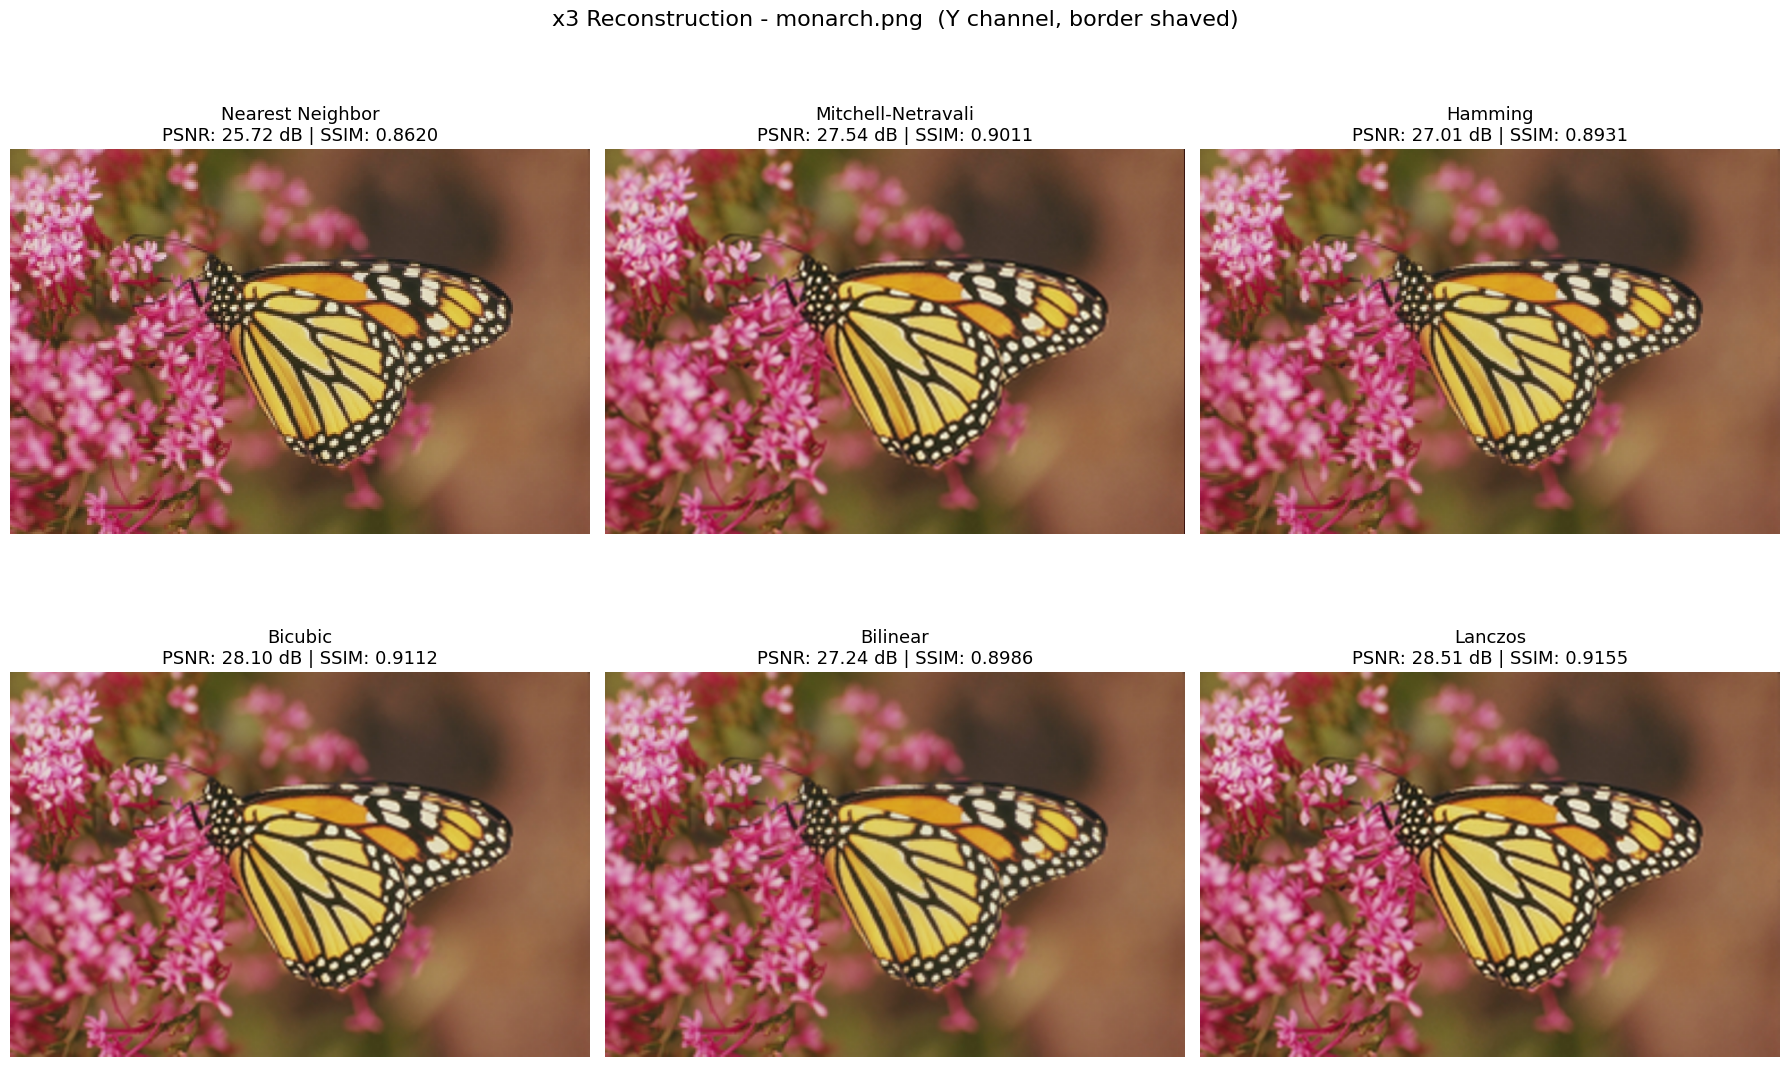

In [11]:
selected_image_name = 'monarch'
selected_image = selected_image_name + '.png'

chosen_path = next(p for p in glob.glob(os.path.join(DATASET_DIR, "**", "*"), recursive=True) if os.path.basename(p) == selected_image)

hr = load_hr(chosen_path, SCALE)
results, outputs = evaluate_image(hr, SCALE)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for ax, name in zip(axes.ravel(), METHODS):
    p, s = results[name]
    ax.imshow(outputs[name])
    ax.set_title(f"{name}\nPSNR: {p:.2f} dB | SSIM: {s:.4f}", fontsize=13)
    ax.axis("off")

fig.suptitle(f"x{SCALE} Reconstruction - {selected_image}  (Y channel, border shaved)", fontsize=16)
plt.tight_layout()
plt.show()

## 9. Upscale a single patch
The **whole image** is downscaled by `SCALE` and upscaled again with every method (same protocol as the SRCNN notebook), and only then the selected patch is cut from the ground truth and from every reconstruction. This way the patch borders see real neighbouring pixels instead of padded ones, and the numbers are comparable with the SRCNN notebook. PSNR and SSIM (Y channel) are written above each result. Edit `patch_image`, `patch_x/patch_y`, `patch_w/patch_h` and `shave` at the top of the next cells.

`shave` is the border removed from the **patch** before PSNR. The default is `0` (same as `psnr_mode='patch'` in the SRCNN notebook), because the patch edges are not the image edges.

`via_rgb=True` (default) computes the patch PSNR on the Y channel read back from the RGB patch (Y -> RGB -> Y), which is exactly what the SRCNN notebook does, so the numbers match. Set `via_rgb=False` to evaluate the reconstructed Y directly (no colour round trip).

SSIM uses the same 11x11 Gaussian window as the rest of the notebook (no padding), so it is computed on the patch interior; on a 99x99 patch with `shave = 0` the SSIM map is 89x89. `best` (green title) is chosen by PSNR.

In [12]:
def reconstruct_full_y(hr, scale):
    w, h = hr.size
    lr_size = (w // scale, h // scale)
    y_gt, cb, cr = hr.convert("YCbCr").split()
    y_lr  = y_gt.resize(lr_size, DOWNSCALE_METHOD)
    cb_up = cb.resize(lr_size, DOWNSCALE_METHOD).resize((w, h), CHROMA_METHOD)
    cr_up = cr.resize(lr_size, DOWNSCALE_METHOD).resize((w, h), CHROMA_METHOD)
    y_ups = {name: upscale_y(y_lr, scale, m) for name, m in METHODS.items()}
    return y_gt, y_lr, y_ups, cb_up, cr_up


def prepare_patch(patch_image, patch_x, patch_y, patch_w, patch_h, shave, via_rgb=True):
    chosen_path = next(p for p in glob.glob(os.path.join(DATASET_DIR, "**", "*"), recursive=True)
                       if os.path.splitext(os.path.basename(p))[0] == patch_image)
    hr = load_hr(chosen_path, SCALE)
    W, H = hr.size

    pw = max(1, min(patch_w, W)); ph = max(1, min(patch_h, H))
    px = max(0, min(patch_x, W - pw)); py = max(0, min(patch_y, H - ph))
    box = (px, py, px + pw, py + ph)
    if (pw, ph, px, py) != (patch_w, patch_h, patch_x, patch_y):
        print(f"[note] patch adjusted to x={px}, y={py}, {pw}x{ph} (image is {W}x{H})")
    assert min(pw, ph) > 2 * shave, "patch is too small for this shave value"

    y_gt, y_lr, y_ups, cb_up, cr_up = reconstruct_full_y(hr, SCALE)

    y_gt_p = y_gt.crop(box)
    hr_patch = hr.crop(box)
    patch_psnr, patch_ssim, patch_out = {}, {}, {}
    for name, y_up in y_ups.items():
        y_up_p = y_up.crop(box)
        patch_out[name] = Image.merge("YCbCr", (y_up_p, cb_up.crop(box), cr_up.crop(box))).convert("RGB")
        if via_rgb:   # same as the SRCNN notebook: Y is read back from the RGB image
            y_eval = patch_out[name].convert("YCbCr").split()[0]
        else:
            y_eval = y_up_p
        patch_psnr[name] = compute_psnr(y_gt_p, y_eval, shave)
        # SSIM uses an 11x11 window ('valid'), so the patch must be larger than 10 px after shaving
        patch_ssim[name] = compute_ssim(y_gt_p, y_eval, shave) if min(pw, ph) - 2 * shave > 10 else float('nan')

    lr_box = (px // SCALE, py // SCALE, -(-(px + pw) // SCALE), -(-(py + ph) // SCALE))
    lr_patch = y_lr.crop(lr_box).convert("RGB")
    return hr, hr_patch, lr_patch, patch_out, patch_psnr, patch_ssim, (px, py, pw, ph)


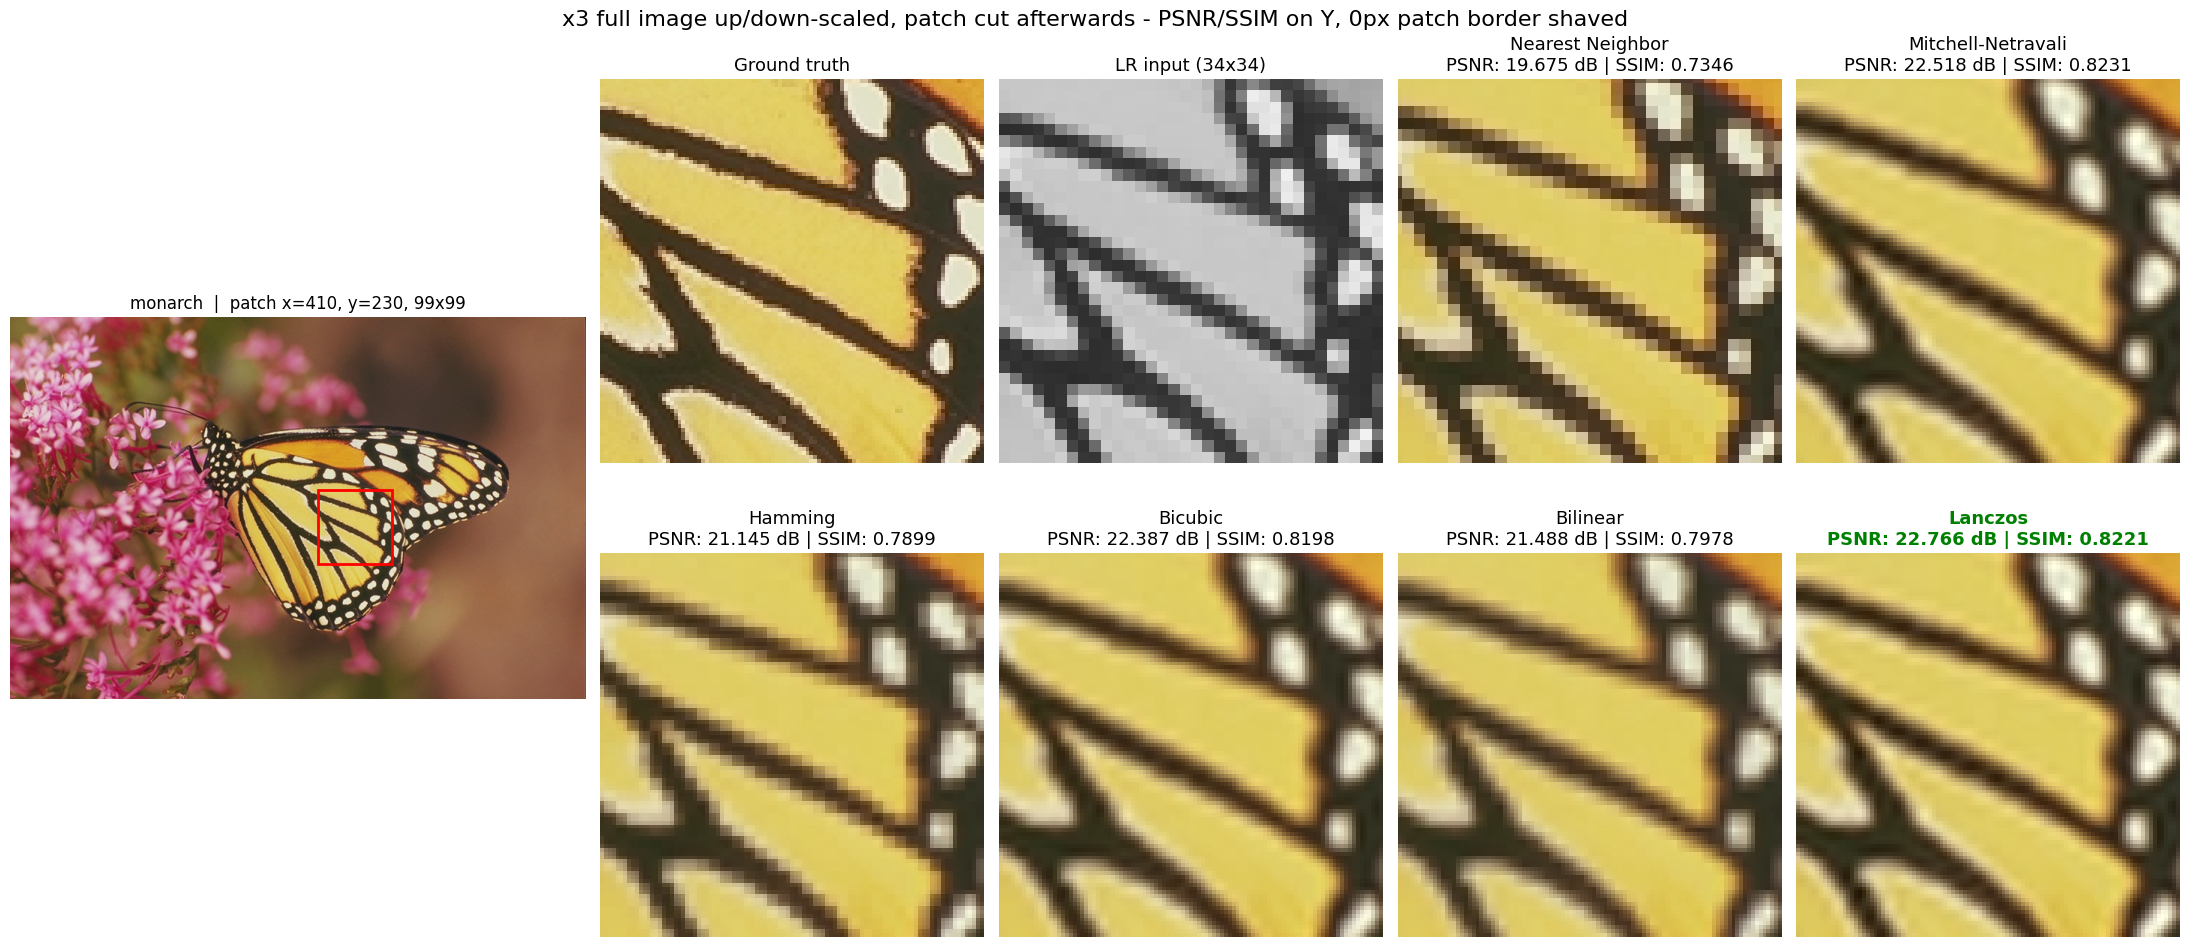

In [13]:
patch_image = 'monarch'

patch_x = 410
patch_y = 230
patch_w = 99
patch_h = 99

shave = 0
via_rgb = True
hr, hr_patch, lr_patch, patch_out, patch_psnr, patch_ssim, (px, py, pw, ph) = prepare_patch(
    patch_image, patch_x, patch_y, patch_w, patch_h, shave, via_rgb)
best = max(patch_psnr, key=patch_psnr.get)

fig = plt.figure(figsize=(22, 10))
gs = GridSpec(2, 5, width_ratios=[1.5, 1, 1, 1, 1], figure=fig)

ax0 = fig.add_subplot(gs[:, 0])
ax0.imshow(hr)
ax0.add_patch(patches.Rectangle((px, py), pw, ph, fill=False, edgecolor="red", linewidth=2))
ax0.set_title(f"{patch_image}  |  patch x={px}, y={py}, {pw}x{ph}")
ax0.axis("off")

panels = [("Ground truth", hr_patch),
          (f"LR input ({lr_patch.size[0]}x{lr_patch.size[1]})", lr_patch)] + list(patch_out.items())
for i, (title, im) in enumerate(panels):
    ax = fig.add_subplot(gs[i // 4, 1 + i % 4])
    ax.imshow(im, interpolation="nearest")
    if title in patch_psnr:
        is_best = title == best
        ax.set_title(f"{title}\nPSNR: {patch_psnr[title]:.3f} dB | SSIM: {patch_ssim[title]:.4f}", fontsize=13,
                     color="green" if is_best else "black", fontweight="bold" if is_best else "normal")
    else:
        ax.set_title(title, fontsize=13)
    ax.axis("off")

fig.suptitle(f"x{SCALE} full image up/down-scaled, patch cut afterwards - PSNR/SSIM on Y, {shave}px patch border shaved", fontsize=16)
plt.tight_layout()
plt.show()


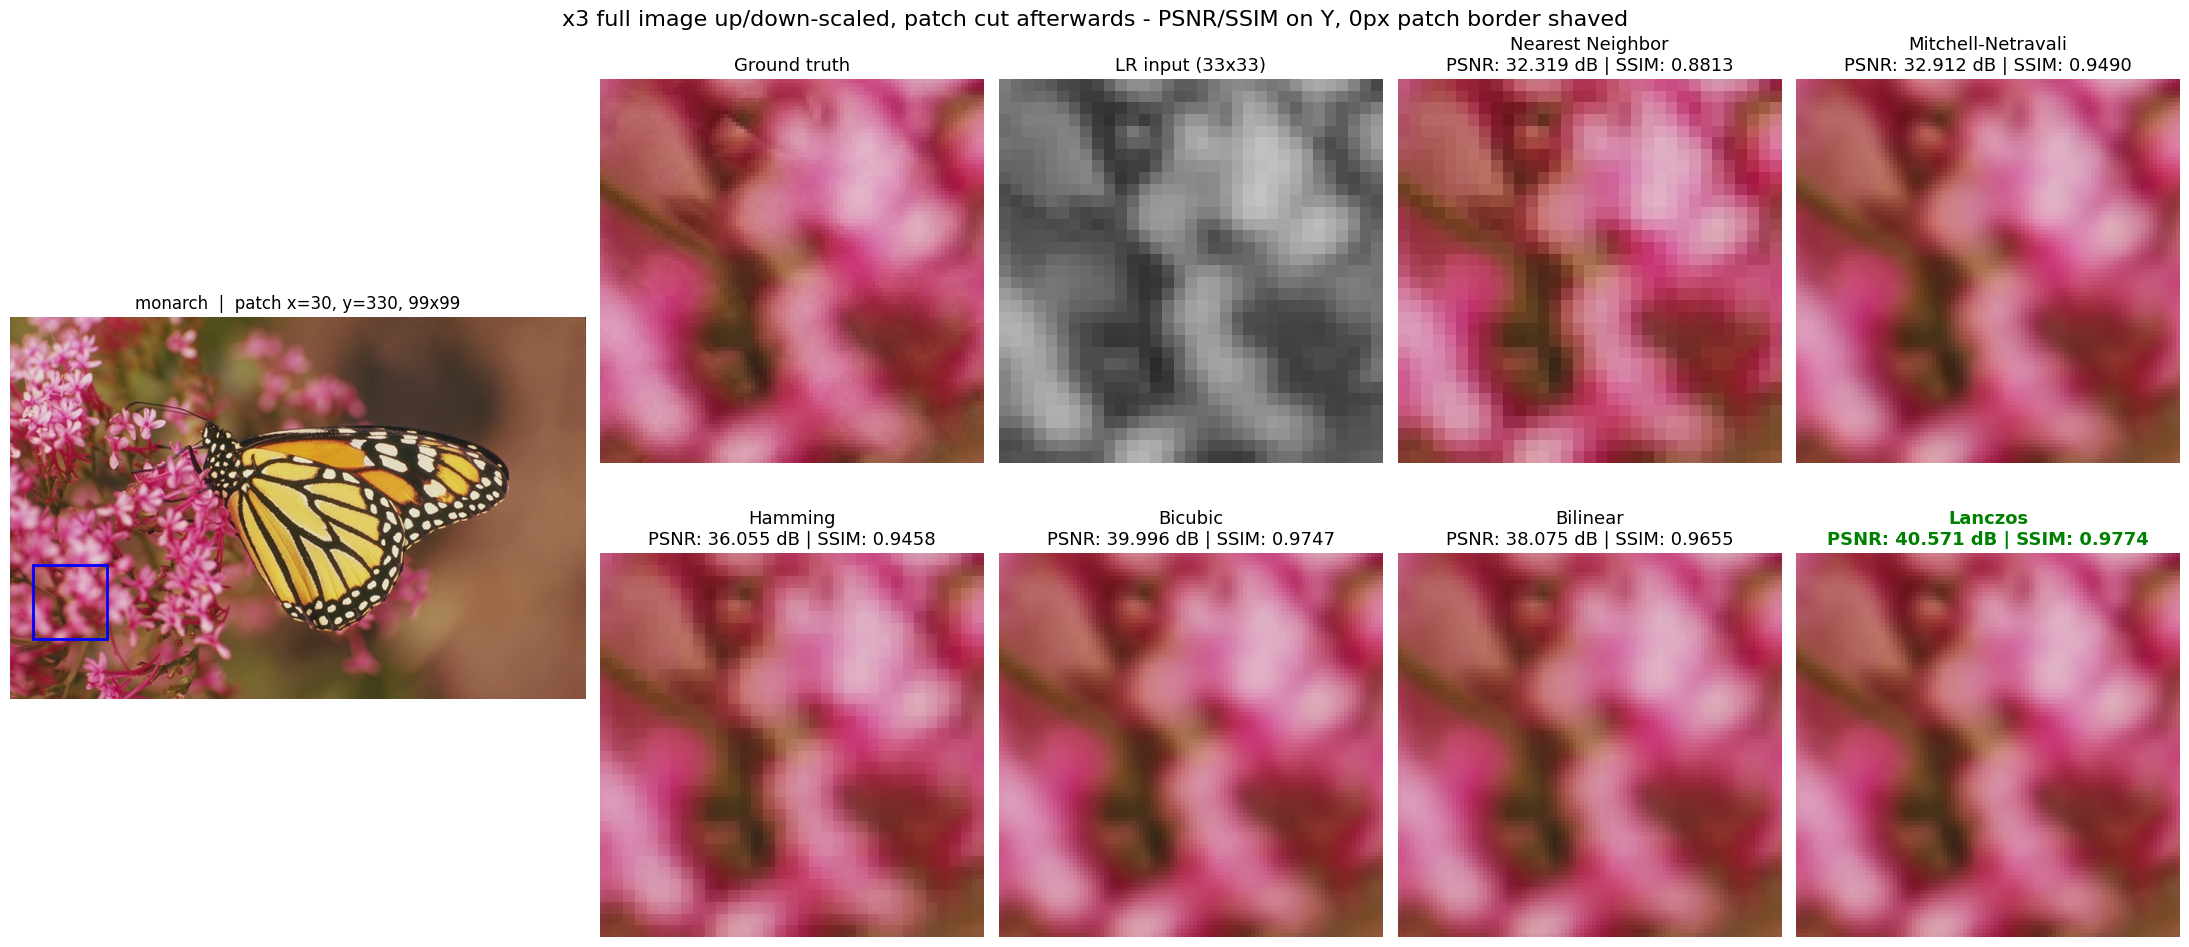

In [14]:
patch_x = 30
patch_y = 330
patch_w = 99
patch_h = 99

hr, hr_patch, lr_patch, patch_out, patch_psnr, patch_ssim, (px, py, pw, ph) = prepare_patch(
    patch_image, patch_x, patch_y, patch_w, patch_h, shave, via_rgb)
best = max(patch_psnr, key=patch_psnr.get)

fig = plt.figure(figsize=(22, 10))
gs = GridSpec(2, 5, width_ratios=[1.5, 1, 1, 1, 1], figure=fig)

ax0 = fig.add_subplot(gs[:, 0])
ax0.imshow(hr)
ax0.add_patch(patches.Rectangle((px, py), pw, ph, fill=False, edgecolor="blue", linewidth=2))
ax0.set_title(f"{patch_image}  |  patch x={px}, y={py}, {pw}x{ph}")
ax0.axis("off")

panels = [("Ground truth", hr_patch),
          (f"LR input ({lr_patch.size[0]}x{lr_patch.size[1]})", lr_patch)] + list(patch_out.items())
for i, (title, im) in enumerate(panels):
    ax = fig.add_subplot(gs[i // 4, 1 + i % 4])
    ax.imshow(im, interpolation="nearest")
    if title in patch_psnr:
        is_best = title == best
        ax.set_title(f"{title}\nPSNR: {patch_psnr[title]:.3f} dB | SSIM: {patch_ssim[title]:.4f}", fontsize=13,
                     color="green" if is_best else "black", fontweight="bold" if is_best else "normal")
    else:
        ax.set_title(title, fontsize=13)
    ax.axis("off")

fig.suptitle(f"x{SCALE} full image up/down-scaled, patch cut afterwards - PSNR/SSIM on Y, {shave}px patch border shaved", fontsize=16)
plt.tight_layout()
plt.show()
